# PowerMLP: An Efficient Version of KAN
## PyTorch implementation and reproducible Colab experiment

**Paper:** Qiu et al., AAAI 2025, [DOI](https://doi.org/10.1609/aaai.v39i19.34210). [Official implementation](https://github.com/Reed-qiuu/PowerMLP).

This notebook implements Eq. (6) and runs a reduced experiment on the paper's section 5.4 function, $f(x,y)=x e^{-y}$. It compares PowerMLP, a ReLU MLP, a custom fixed-grid spline KAN, and two ablations. It is **not a full replication** of all paper experiments or the reported 40× speedup.

### Run in Google Colab
Select **Runtime → Run all**. CPU is sufficient. To use a GPU, select it under **Runtime → Change runtime type** and change DEVICE below to `cuda`. No dataset download, account key, Drive mounting, or paid service is needed. This notebook includes its own source code, so it also works after uploading this file alone.

Saved example outputs, if present, came from a local CPU execution; rerun to obtain your Colab results.

In [1]:
import importlib.util, subprocess, sys
packages = {'torch':'torch>=2.2,<3', 'numpy':'numpy>=1.26,<3', 'scipy':'scipy>=1.12,<2', 'matplotlib':'matplotlib>=3.8,<4'}
missing = [spec for name,spec in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import torch, numpy as np
print('PyTorch:', torch.__version__, 'NumPy:', np.__version__)
print('CUDA available:', torch.cuda.is_available())

PyTorch: 2.15.0 NumPy: 2.5.5
CUDA available: False


## 1. Exact layer equation
For each hidden layer:
$$h_{l+1}=\alpha_l\,\operatorname{SiLU}(h_l)+[\max(0,W_lh_l+b_l)]^k.$$
The output layer is affine only. The default is $k=3$. The basis acts on the **input** to the layer, before its own bias-free linear projection. PyTorch autograd differentiates both paths.

The next cell defines the complete implementation and training code. The KAN uses Cox–de Boor recursion on a fixed grid. It omits pykan's adaptive grid, pruning, and symbolic functionality, so timings describe this implementation only.

In [2]:
from pathlib import Path
p = Path('src/__init__.py')
p.parent.mkdir(parents=True, exist_ok=True)
p.write_text('')
print('Wrote', p)

Wrote src/__init__.py


In [3]:
from pathlib import Path
p = Path('src/models.py')
p.parent.mkdir(parents=True, exist_ok=True)
p.write_text('"""Independent implementation of Qiu et al. (AAAI 2025), Eq. (6)."""\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\n\nclass PowerLayer(nn.Module):\n    def __init__(self, in_features, out_features, k=3, basis=True):\n        super().__init__()\n        if not isinstance(k, int) or k < 1:\n            raise ValueError(\'k must be a positive integer\')\n        self.k = k\n        self.affine = nn.Linear(in_features, out_features)\n        self.basis = nn.Linear(in_features, out_features, bias=False) if basis else None\n\n    def forward(self, x):\n        out = F.relu(self.affine(x)).pow(self.k)\n        return out + self.basis(F.silu(x)) if self.basis is not None else out\n\nclass PowerMLP(nn.Module):\n    def __init__(self, widths=(2, 32, 8, 1), k=3, basis=True):\n        super().__init__()\n        if len(widths) < 2 or any(w < 1 for w in widths):\n            raise ValueError(\'widths must contain at least two positive sizes\')\n        self.layers = nn.Sequential(*[\n            PowerLayer(a, b, k, basis) for a, b in zip(widths[:-2], widths[1:-1])\n        ], nn.Linear(widths[-2], widths[-1]))\n\n    def forward(self, x):\n        return self.layers(x)\n\nclass MLP(nn.Module):\n    def __init__(self, widths=(2, 32, 18, 1)):\n        super().__init__()\n        layers = []\n        for i, (a, b) in enumerate(zip(widths[:-1], widths[1:])):\n            layers.append(nn.Linear(a, b))\n            if i < len(widths)-2:\n                layers.append(nn.ReLU())\n        self.layers = nn.Sequential(*layers)\n\n    def forward(self, x):\n        return self.layers(x)\n\nclass SplineKANLayer(nn.Module):\n    """Fixed uniform grid KAN, Eqs. (1)-(4); no adaptive grid or symbolic branch.\n\n    Each edge has independent base and spline scales plus G+k coefficients.\n    Vectorizes basis evaluation across edges. This is NOT pykan\'s runtime.\n    """\n    def __init__(self, in_features, out_features, grid_size=3, k=3, grid_range=(-1., 1.)):\n        super().__init__()\n        if grid_size < 1 or k < 1 or grid_range[0] >= grid_range[1]:\n            raise ValueError(\'invalid grid settings\')\n        self.k = k\n        step = (grid_range[1]-grid_range[0])/grid_size\n        grid = torch.arange(-k, grid_size+k+1)*step+grid_range[0]\n        self.register_buffer(\'grid\', grid)\n        self.base_weight = nn.Parameter(torch.empty(out_features, in_features))\n        self.spline_scale = nn.Parameter(torch.ones(out_features, in_features))\n        self.coefficients = nn.Parameter(torch.empty(out_features, in_features, grid_size+k))\n        nn.init.kaiming_uniform_(self.base_weight, a=5**0.5)\n        nn.init.normal_(self.coefficients, std=0.05)\n\n    def bsplines(self, x):\n        t = self.grid\n        z = x.unsqueeze(-1)\n        b = ((z >= t[:-1]) & (z < t[1:])).to(x.dtype)\n        for degree in range(1, self.k+1):\n            b = ((z-t[:-(degree+1)]) / (t[degree:-1]-t[:-(degree+1)]) * b[..., :-1]\n                 + (t[degree+1:]-z) / (t[degree+1:]-t[1:-degree]) * b[..., 1:])\n        return b\n\n    def forward(self, x):\n        spline = torch.einsum(\'bik,oik->bo\', self.bsplines(x),\n                              self.coefficients*self.spline_scale.unsqueeze(-1))\n        return F.linear(F.silu(x), self.base_weight) + spline\n\nclass SplineKAN(nn.Module):\n    def __init__(self, widths=(2, 2, 1, 1), grid_size=100, k=3):\n        super().__init__()\n        self.layers = nn.Sequential(*[SplineKANLayer(a,b,grid_size,k) for a,b in zip(widths[:-1],widths[1:])])\n\n    def forward(self, x):\n        return self.layers(x)\n\ndef count_parameters(model):\n    return sum(p.numel() for p in model.parameters() if p.requires_grad)\n')
print('Wrote', p)

Wrote src/models.py


In [4]:
from pathlib import Path
p = Path('src/experiment.py')
p.parent.mkdir(parents=True, exist_ok=True)
p.write_text('"""Colab-sized experiments; faithful architecture, deliberately reduced protocol."""\nimport argparse, copy, csv, json, platform, time\nfrom pathlib import Path\nimport numpy as np\nimport torch\nfrom torch import nn\nfrom .models import PowerMLP, MLP, SplineKAN, count_parameters\n\n\ndef make_data(seed, n=2048):\n    generator = torch.Generator().manual_seed(seed)\n    x = torch.rand(n,2,generator=generator)*2-1\n    # Paper section 5.4 ablation target. Domain/split are our choices.\n    y = x[:,0:1]*torch.exp(-x[:,1:2])\n    return x,y\n\n\ndef synchronize(device):\n    if device.type == \'cuda\': torch.cuda.synchronize(device)\n\n\ndef benchmark(model,x,steps=100):\n    # Separate steady-state forward/backward microbenchmark; includes no optimizer.\n    for _ in range(10):\n        model.zero_grad(set_to_none=True); model(x).square().mean().backward()\n    synchronize(x.device); start=time.perf_counter()\n    for _ in range(steps):\n        model.zero_grad(set_to_none=True); model(x).square().mean().backward()\n    synchronize(x.device)\n    return (time.perf_counter()-start)*1000/steps\n\n\ndef run(steps=1000,seeds=(0,1,2),size=\'large\',device=\'cpu\',out=\'results\'):\n    if steps < 1 or not seeds: raise ValueError(\'positive steps and at least one seed required\')\n    torch.set_num_threads(1)\n    device=torch.device(device)\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    power_shape=(2,4,1) if size==\'small\' else (2,32,8,1)\n    mlp_shape=(2,6,1) if size==\'small\' else (2,32,18,1)\n    kan_shape=(2,1,1) if size==\'small\' else (2,2,1,1)\n    grid=3 if size==\'small\' else 100\n    factories={\n      \'PowerMLP\':lambda:PowerMLP(power_shape),\n      \'MLP\':lambda:MLP(mlp_shape),\n      \'SplineKAN\':lambda:SplineKAN(kan_shape,grid),\n      \'No basis\':lambda:PowerMLP(power_shape,basis=False),\n      \'ReLU instead of ReLU^3\':lambda:PowerMLP(power_shape,k=1),\n    }\n    rows=[]; histories={}; predictions={}\n    for seed in seeds:\n      train_x,train_y=make_data(1000+seed,1024)\n      val_x,val_y=make_data(2000+seed,256)\n      test_x,test_y=make_data(3000+seed,1024)\n      train_x,train_y,val_x,val_y,test_x,test_y=[t.to(device) for t in (train_x,train_y,val_x,val_y,test_x,test_y)]\n      for name,factory in factories.items():\n        torch.manual_seed(seed)\n        model=factory().to(device)\n        opt=torch.optim.Adam(model.parameters(),lr=1e-3)\n        best=float(\'inf\');state=None;history=[];best_step=0\n        synchronize(device);start=time.perf_counter()\n        for step in range(1,steps+1):\n          model.train();opt.zero_grad(set_to_none=True)\n          loss=nn.functional.mse_loss(model(train_x),train_y)\n          if not torch.isfinite(loss): raise RuntimeError(f\'Nonfinite loss: {name}, seed={seed}\')\n          loss.backward();opt.step()\n          if step==1 or step%25==0 or step==steps:\n            model.eval()\n            with torch.no_grad(): val=nn.functional.mse_loss(model(val_x),val_y).item()\n            history.append({\'step\':step,\'train_mse\':loss.item(),\'val_rmse\':val**0.5})\n            if val < best: best=val;state=copy.deepcopy(model.state_dict());best_step=step\n        synchronize(device);elapsed=time.perf_counter()-start\n        model.load_state_dict(state);model.eval()\n        with torch.no_grad():\n          pred=model(test_x);error=pred-test_y\n          rmse=error.square().mean().sqrt().item();mae=error.abs().mean().item()\n          r2=1-error.square().sum().item()/((test_y-test_y.mean()).square().sum().item())\n        ms=benchmark(model,train_x[:256])\n        row=dict(model=name,seed=seed,parameters=count_parameters(model),test_rmse=rmse,test_mae=mae,test_r2=r2,training_seconds=elapsed,step_ms=ms,best_step=best_step)\n        rows.append(row);histories[f\'{name}/{seed}\']=history\n        if seed==seeds[0]:\n          predictions[name]=pred.cpu().numpy().ravel().tolist()\n          torch.save(model.state_dict(),out/(name.replace(\' \',\'_\').replace(\'^\',\'\')+\'.pt\'))\n        print(json.dumps(row),flush=True)\n    summary=[]\n    for name in factories:\n      subset=[r for r in rows if r[\'model\']==name]\n      item={\'model\':name,\'parameters\':subset[0][\'parameters\']}\n      for metric in (\'test_rmse\',\'test_mae\',\'test_r2\',\'training_seconds\',\'step_ms\'):\n        values=[r[metric] for r in subset]\n        item[metric+\'_mean\']=float(np.mean(values))\n        item[metric+\'_std\']=float(np.std(values,ddof=1)) if len(values)>1 else 0.\n      summary.append(item)\n    results={\'scope\':\'Reduced protocol, exact PowerMLP architecture; custom fixed-grid KAN, not pykan runtime or full paper reproduction\',\n      \'config\':{\'steps\':steps,\'seeds\':list(seeds),\'size\':size,\'device\':str(device),\'domain\':[-1,1],\'train\':1024,\'validation\':256,\'test\':1024,\'optimizer\':\'Adam\',\'learning_rate\':.001,\'batch\':\'full\',\'selection\':\'lowest validation MSE, checked every 25 steps\',\'target\':\'x * exp(-y)\'},\n      \'environment\':{\'python\':platform.python_version(),\'torch\':torch.__version__,\'numpy\':np.__version__,\'platform\':platform.platform(),\'threads\':torch.get_num_threads(),\'accelerator\':torch.cuda.get_device_name(device) if device.type==\'cuda\' else \'CPU\'},\n      \'runs\':rows,\'summary\':summary}\n    (out/\'results.json\').write_text(json.dumps(results,indent=2))\n    (out/\'history.json\').write_text(json.dumps(histories,indent=2))\n    with (out/\'results.csv\').open(\'w\',newline=\'\') as f:\n      w=csv.DictWriter(f,fieldnames=rows[0]);w.writeheader();w.writerows(rows)\n    plot_results(out,histories,summary)\n    return results\n\n\ndef plot_results(out,histories,summary):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    plt.rcParams.update({\'font.size\':12,\'axes.spines.top\':False,\'axes.spines.right\':False})\n    fig,ax=plt.subplots(figsize=(10,5))\n    for key,series in histories.items():\n      if key.endswith(\'/0\'):\n        ax.semilogy([r[\'step\'] for r in series],[r[\'val_rmse\'] for r in series],label=key.rsplit(\'/\',1)[0])\n    ax.set(xlabel=\'Training step\',ylabel=\'Validation RMSE\',title=\'Convergence on x exp(-y), seed 0\');ax.legend();fig.tight_layout()\n    fig.savefig(out/\'convergence.png\',dpi=180);plt.close(fig)\n    fig,ax=plt.subplots(figsize=(10,5))\n    ax.bar([r[\'model\'] for r in summary],[r[\'test_rmse_mean\'] for r in summary],yerr=[r[\'test_rmse_std\'] for r in summary],capsize=4,color=\'#167d9a\')\n    ax.set(ylabel=\'Test RMSE (mean ± sample SD)\',title=\'Independent test split; lower is better\')\n    ax.tick_params(axis=\'x\',labelsize=9);fig.tight_layout();fig.savefig(out/\'comparison.png\',dpi=180);plt.close(fig)\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--steps\',type=int,default=1000);p.add_argument(\'--seeds\',type=int,nargs=\'+\',default=[0,1,2]);p.add_argument(\'--size\',choices=[\'small\',\'large\'],default=\'large\');p.add_argument(\'--device\',default=\'cpu\');p.add_argument(\'--out\',default=\'results\')\n    run(**vars(p.parse_args()))\n')
print('Wrote', p)

Wrote src/experiment.py


In [5]:
from pathlib import Path
p = Path('tests/test_models.py')
p.parent.mkdir(parents=True, exist_ok=True)
p.write_text("import unittest\nimport torch\nimport numpy as np\nfrom scipy.interpolate import BSpline\nfrom src.models import PowerLayer, PowerMLP, MLP, SplineKAN, SplineKANLayer, count_parameters\n\nclass ArchitectureTests(unittest.TestCase):\n    def test_exact_equation(self):\n        torch.manual_seed(42)\n        layer = PowerLayer(2,3).double()\n        x = torch.randn(5,2,dtype=torch.float64)\n        expected = torch.relu(x @ layer.affine.weight.T + layer.affine.bias)**3\n        expected += (x*torch.sigmoid(x)) @ layer.basis.weight.T\n        torch.testing.assert_close(layer(x),expected)\n\n    def test_gradients_parameters_and_input(self):\n        from torch.func import functional_call\n        layer = PowerLayer(2,3).double()\n        x = torch.tensor([[0.2,-0.4],[0.7,0.3]],dtype=torch.float64,requires_grad=True)\n        params = dict(layer.named_parameters())\n        names = list(params)\n        def fn(x,*values):\n            return functional_call(layer,dict(zip(names,values)),(x,))\n        self.assertTrue(torch.autograd.gradcheck(fn,(x,*params.values()),eps=1e-6,atol=1e-5))\n\n    def test_parameter_counts(self):\n        self.assertEqual(count_parameters(PowerMLP((2,4,1))),25)\n        self.assertEqual(count_parameters(MLP((2,6,1))),25)\n        self.assertEqual(count_parameters(SplineKAN((2,1,1),3)),24)\n        self.assertEqual(count_parameters(PowerMLP()),689)\n        self.assertEqual(count_parameters(MLP()),709)\n        self.assertEqual(count_parameters(SplineKAN()),735)\n\n    def test_splines_against_scipy(self):\n        layer = SplineKANLayer(2,3).double()\n        x = torch.linspace(-.99,.99,17,dtype=torch.float64).reshape(-1,1).repeat(1,2)\n        t = layer.grid.numpy()\n        n = len(t)-layer.k-1\n        reference = BSpline(t,np.eye(n),layer.k)(x.numpy())\n        np.testing.assert_allclose(layer.bsplines(x).numpy(),reference,atol=1e-12)\n        torch.testing.assert_close(layer.bsplines(x).sum(-1),torch.ones_like(x))\n\n    def test_linear_output_and_backward(self):\n        for model in [PowerMLP(),MLP(),SplineKAN()]:\n            y=model(torch.randn(7,2))\n            self.assertEqual(y.shape,(7,1))\n            y.square().mean().backward()\n            self.assertTrue(all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters()))\n        self.assertIsInstance(PowerMLP().layers[-1],torch.nn.Linear)\n\nif __name__ == '__main__':\n    unittest.main()\n")
print('Wrote', p)

Wrote tests/test_models.py


## 2. Correctness checks
Verify the equation, numerical gradients (inputs and every trainable parameter), parameter counts, the linear output, and B-splines against SciPy.

In [6]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'], check=True)

test_exact_equation (test_models.ArchitectureTests.test_exact_equation) ... 

ok
test_gradients_parameters_and_input (test_models.ArchitectureTests.test_gradients_parameters_and_input) ... 

ok
test_linear_output_and_backward (test_models.ArchitectureTests.test_linear_output_and_backward) ... ok
test_parameter_counts (test_models.ArchitectureTests.test_parameter_counts) ... ok
test_splines_against_scipy (test_models.ArchitectureTests.test_splines_against_scipy) ... ok

----------------------------------------------------------------------
Ran 5 tests in 1.144s

OK


CompletedProcess(args=['/private/tmp/powermlp-venv/bin/python', '-m', 'unittest', 'discover', '-s', 'tests', '-v'], returncode=0)

## 3. Experiment configuration
The large setting uses the paper's shapes: PowerMLP [2,32,8,1] (689 parameters), MLP [2,32,18,1] (709), and KAN [2,2,1,1] with G=100 (735). The small setting uses 25, 25, and 24 parameters.

Our protocol: uniform inputs in [-1,1]²; 1,024 train, 256 validation, and 1,024 independent test examples per seed; Adam at 0.001; full batches; 1,000 updates. Select the best validation checkpoint, then evaluate the held-out test set. All models see the same split for a given seed. Ablations retain widths, so removing the basis also reduces parameter count.

The paper used different benchmark protocols and an RTX 4090 for timings. Equal update counts do not establish equal convergence or a universal speed ratio.

In [7]:
STEPS = 1000
SEEDS = [0, 1, 2]
SIZE = 'large'
DEVICE = 'cpu'  # change to 'cuda' only after enabling a GPU
OUTPUT = 'results'

In [8]:
from src.experiment import run
results = run(steps=STEPS, seeds=SEEDS, size=SIZE, device=DEVICE, out=OUTPUT)

{"model": "PowerMLP", "seed": 0, "parameters": 689, "test_rmse": 0.010078351944684982, "test_mae": 0.007343757431954145, "test_r2": 0.9998317011821131, "training_seconds": 1.4085282920132158, "step_ms": 0.5692274999455549, "best_step": 1000}


{"model": "MLP", "seed": 0, "parameters": 709, "test_rmse": 0.016330454498529434, "test_mae": 0.010779347270727158, "test_r2": 0.999558125884583, "training_seconds": 1.2550034589949064, "step_ms": 0.3081700000620913, "best_step": 1000}


{"model": "SplineKAN", "seed": 0, "parameters": 735, "test_rmse": 0.7187435030937195, "test_mae": 0.5323472023010254, "test_r2": 0.1440471331237575, "training_seconds": 23.682133084003, "step_ms": 8.854507499927422, "best_step": 175}


{"model": "No basis", "seed": 0, "parameters": 369, "test_rmse": 0.007515625562518835, "test_mae": 0.005904871039092541, "test_r2": 0.999906409392458, "training_seconds": 1.2395063750009285, "step_ms": 2.293942920077825, "best_step": 1000}


{"model": "ReLU instead of ReLU^3", "seed": 0, "parameters": 689, "test_rmse": 0.013492261059582233, "test_mae": 0.008538361638784409, "test_r2": 0.9996983721427538, "training_seconds": 5.3017663749924395, "step_ms": 1.0582629199780058, "best_step": 1000}


{"model": "PowerMLP", "seed": 1, "parameters": 689, "test_rmse": 0.006588717922568321, "test_mae": 0.004718698561191559, "test_r2": 0.9999295561591008, "training_seconds": 4.2800276249909075, "step_ms": 0.8570412499830127, "best_step": 1000}


... (6 outputs left out)

{"model": "SplineKAN", "seed": 2, "parameters": 735, "test_rmse": 0.7630805969238281, "test_mae": 0.5772728323936462, "test_r2": 0.009309162920694836, "training_seconds": 17.867381832998944, "step_ms": 3.8326587500341702, "best_step": 100}


{"model": "No basis", "seed": 2, "parameters": 369, "test_rmse": 0.004833275452256203, "test_mae": 0.003786676097661257, "test_r2": 0.9999602551954938, "training_seconds": 1.1765653339971323, "step_ms": 0.33042791998013854, "best_step": 1000}


{"model": "ReLU instead of ReLU^3", "seed": 2, "parameters": 689, "test_rmse": 0.020741412416100502, "test_mae": 0.012961380183696747, "test_r2": 0.999268062566911, "training_seconds": 0.9710118750081165, "step_ms": 0.7054766699729953, "best_step": 1000}


Matplotlib is building the font cache; this may take a moment.


## 4. Results and interpretation
RMSE and MAE are errors, so lower is better. R² measures explained variation. The CSV holds each seed separately; JSON also records the environment and configuration. Error bars are sample standard deviations, not confidence intervals.

Training time includes validation and checkpoint selection. The separate 256-example forward/backward microbenchmark has ten warmup iterations and CUDA synchronization when relevant. It excludes optimizer updates. Hardware and implementation differences affect timing.

PowerMLP                  parameters= 689  RMSE=0.007208 ± 0.002617  training=2.28s
MLP                       parameters= 709  RMSE=0.020805 ± 0.003984  training=1.04s
SplineKAN                 parameters= 735  RMSE=0.747708 ± 0.025099  training=24.04s
No basis                  parameters= 369  RMSE=0.006439 ± 0.001417  training=1.17s
ReLU instead of ReLU^3    parameters= 689  RMSE=0.018185 ± 0.004070  training=2.68s


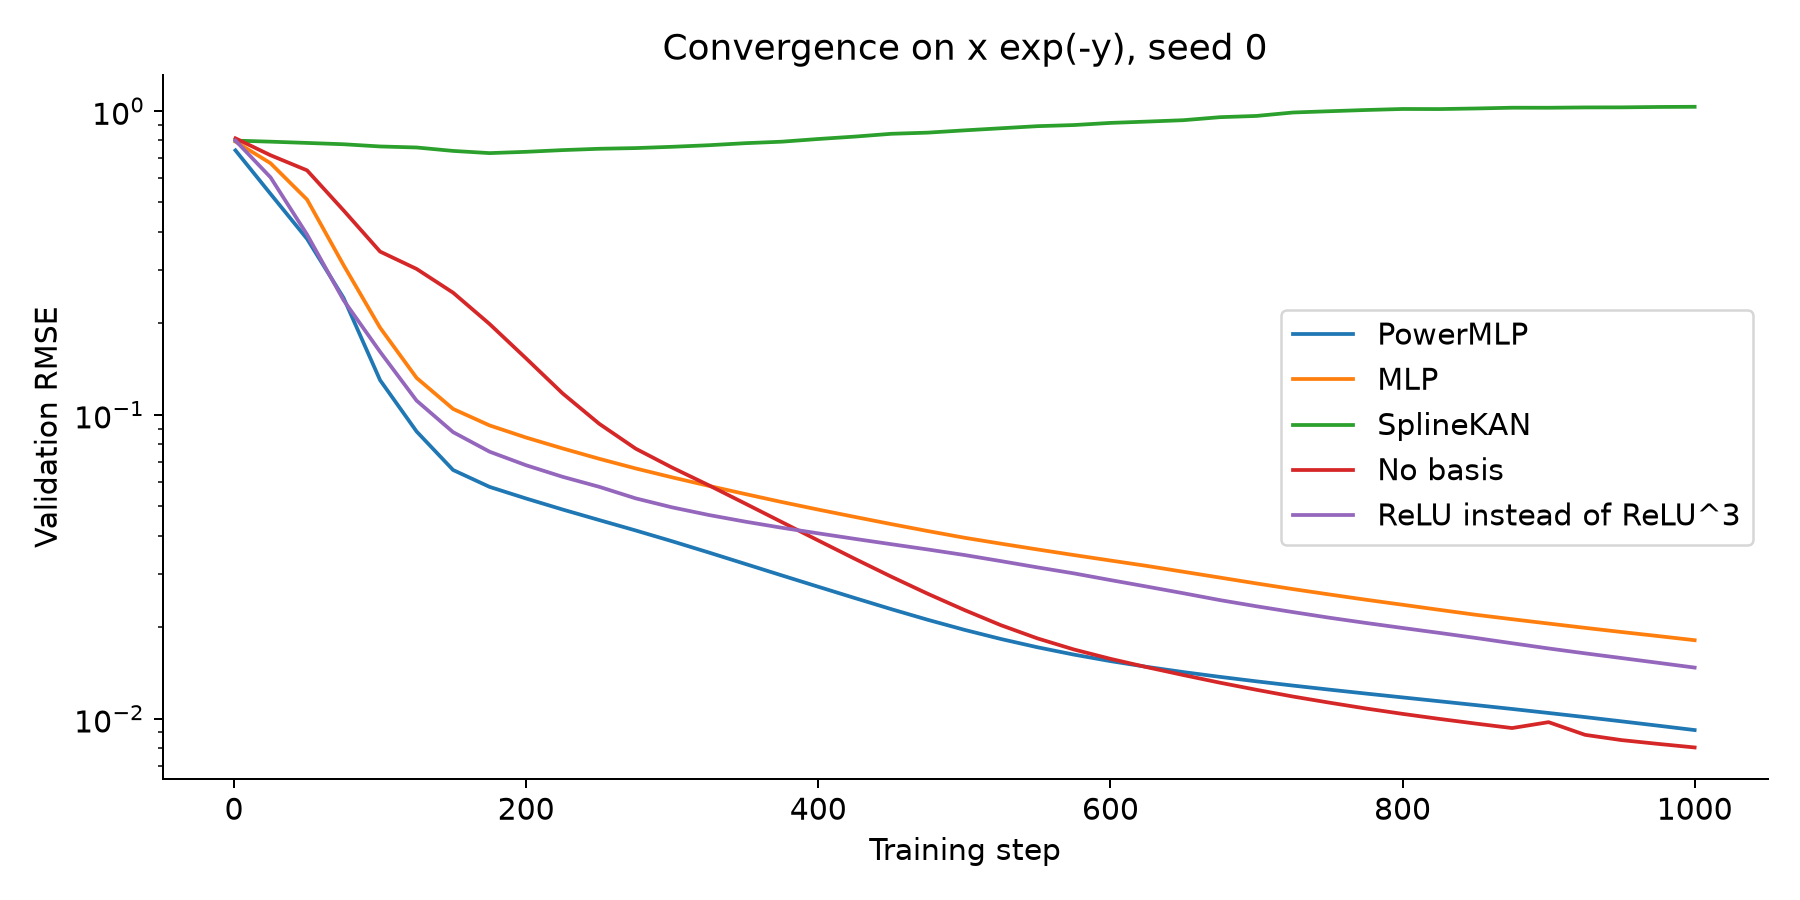

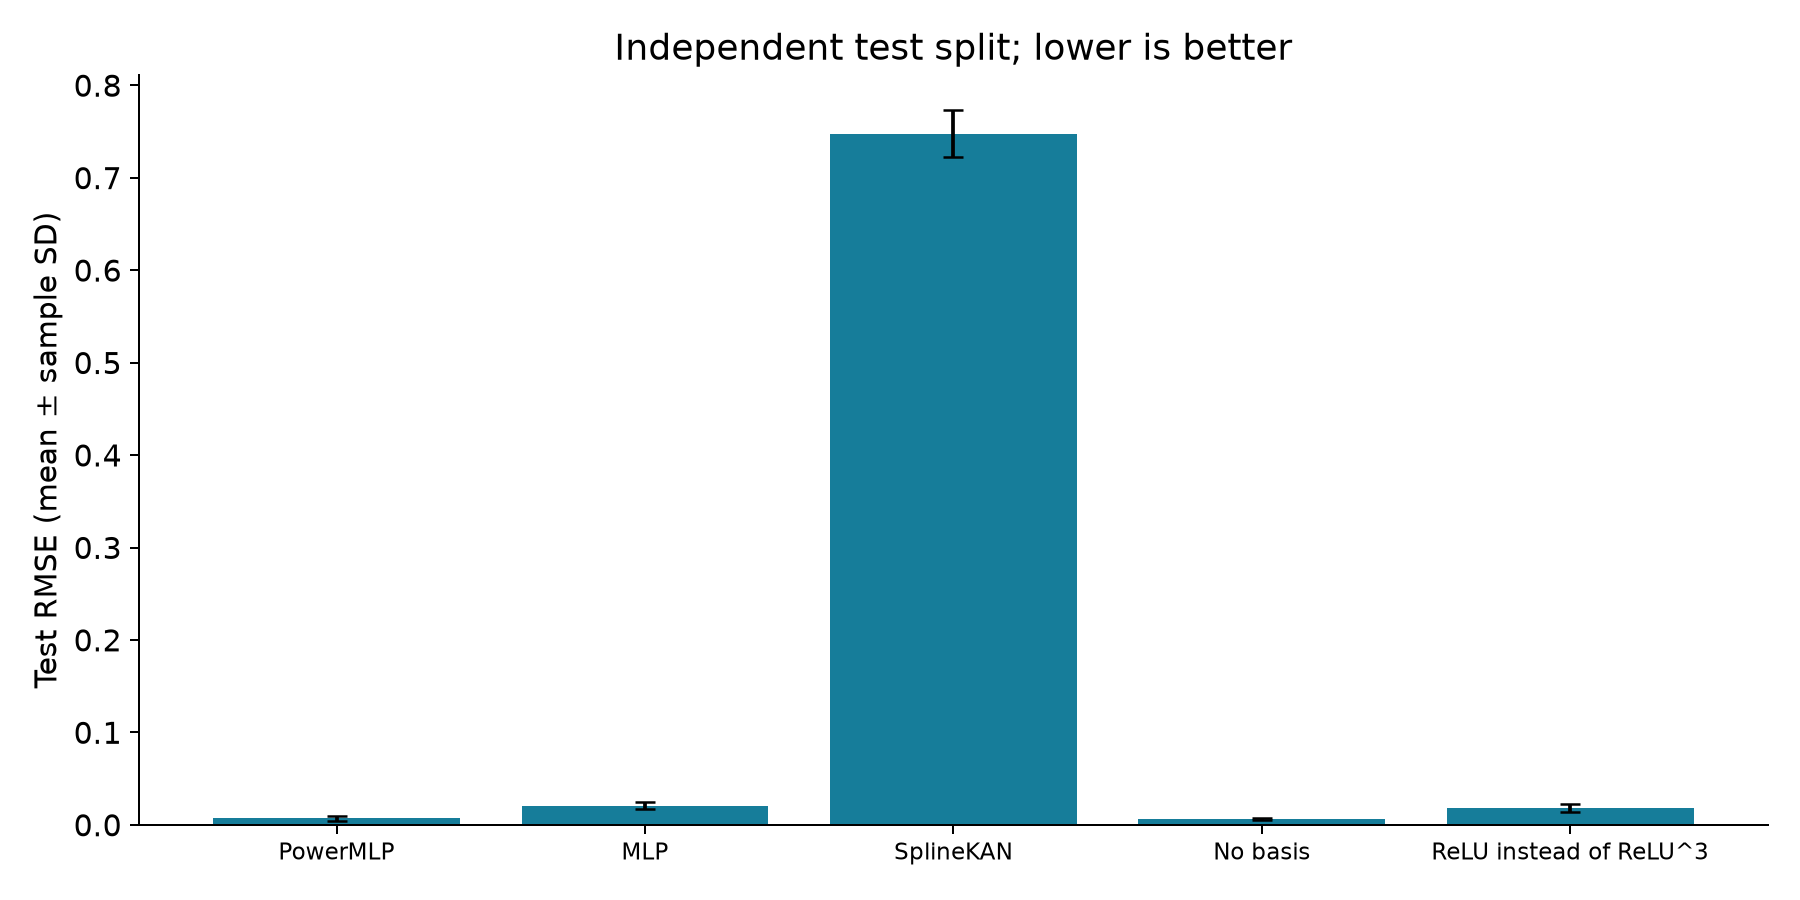

In [9]:
for row in results['summary']:
    print(f"{row['model']:25s} parameters={row['parameters']:4d}  RMSE={row['test_rmse_mean']:.6f} ± {row['test_rmse_std']:.6f}  training={row['training_seconds_mean']:.2f}s")
from IPython.display import display, Image
display(Image(filename=OUTPUT+'/convergence.png'))
display(Image(filename=OUTPUT+'/comparison.png'))

## 5. Try a trained model
This checkpoint is from the first seed and selected on validation loss. The test set never selects model weights.

In [10]:
from src.models import PowerMLP
shape = (2,4,1) if SIZE == 'small' else (2,32,8,1)
model = PowerMLP(shape)
model.load_state_dict(torch.load(OUTPUT+'/PowerMLP.pt', map_location='cpu', weights_only=True))
model.eval()
points = torch.tensor([[0.5,0.2],[-0.5,0.5],[0.0,0.0]])
with torch.no_grad():
    print('Predictions:', model(points).squeeze().tolist())
print('True values:', (points[:,0]*torch.exp(-points[:,1])).tolist())

Predictions: [0.40069815516471863, -0.3058646321296692, 0.0013852417469024658]
True values: [0.40936538577079773, -0.3032653331756592, 0.0]


## 6. Save the experiment
Download the ZIP before Colab disconnects. It includes metrics, figures, configuration, training history, and first-seed checkpoints. To repeat with a larger budget, change STEPS or SEEDS and rerun configuration onward. Use a fresh OUTPUT name to retain previous results.

In [11]:
import shutil
archive = shutil.make_archive('powermlp_results', 'zip', OUTPUT)
print('Saved:', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Local run: archive is available in the working directory.')

Saved: /private/tmp/powermlp-project/powermlp_results.zip
Local run: archive is available in the working directory.


## Scope and limitations
- Implemented: the exact PowerMLP hidden-layer equation, affine output, comparable small/large parameter budgets, regression, validation selection, independent tests, timing, and ablations.
- Simplified: data domain, split, optimizer protocol, and KAN baseline. Our KAN is fixed-grid and vectorized, not pykan 0.2.5.
- Not reproduced: the complete 16-function suite, knot theory, Titanic/Income, text/image classification, theorem proofs, depth sweep, or paper-wide 40× claim.
- One function and three seeds cannot establish general superiority. A weaker result is still a valid observation. Never substitute the paper's numbers for your measured results.

## References
1. Qiu, R. et al. (2025). PowerMLP: An Efficient Version of KAN. AAAI 39(19), 20069–20076. https://doi.org/10.1609/aaai.v39i19.34210
2. Authors' source: https://github.com/Reed-qiuu/PowerMLP
3. PyTorch documentation: https://docs.pytorch.org/docs/stable/nn.html
4. SciPy BSpline reference: https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.BSpline.html